# Part 4 - Leak-free feature pipeline

BFT65B final report, walkthrough notebook. Every number below is read from `reports/` or recomputed live by the same scripts the README lists. Seed: `config.SEED = 42`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import pandas as pd
import polars as pl
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import config as C

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)
R = ROOT / "reports"
print("project root:", ROOT, "| python", sys.version.split()[0], "| polars", pl.__version__, "| seed", C.SEED)


def run(script, *args, tail=25):
    """Run one pipeline script exactly as the README does, and show the end of its output."""
    t = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"})
    lines = (t.stdout + t.stderr).strip().splitlines()
    print("\n".join(lines[-tail:]))
    print(f"\n>>> {script} {' '.join(args)} exited with {t.returncode}")
    assert t.returncode == 0, "step failed"


def csv(name, n=None):
    df = pd.read_csv(R / name)
    display(df if n is None else df.head(n))


def fig(name, width=820):
    display(Image(filename=str(R / name), width=width))

project root: D:\Final BigData | python 3.15.2 | polars 2.1.0 | seed 42


**Goal.** Features that proxy CAMELS risk, built only from information available at each quarter, joined
with the label, and preprocessing fitted on training rows only.

In [2]:
run('src/p4_features.py')

shape: (4, 7)
┌────────────┬─────────┬───────┬────────────┬────────────┬─────────┬──────────────┐
│ _split     ┆ rows    ┆ banks ┆ first_q    ┆ last_q     ┆ y1_rows ┆ failed_banks │
│ ---        ┆ ---     ┆ ---   ┆ ---        ┆ ---        ┆ ---     ┆ ---          │
│ str        ┆ u32     ┆ u32   ┆ date       ┆ date       ┆ i64     ┆ u32          │
╞════════════╪═════════╪═══════╪════════════╪════════════╪═════════╪══════════════╡
│ dev        ┆ 1346634 ┆ 23704 ┆ 1984-03-31 ┆ 2011-12-31 ┆ 10477   ┆ 2755         │
│ gap        ┆ 28805   ┆ 7305  ┆ 2012-03-31 ┆ 2012-12-31 ┆ 129     ┆ 59           │
│ test       ┆ 274032  ┆ 7093  ┆ 2013-03-31 ┆ 2025-06-30 ┆ 254     ┆ 78           │
│ unlabelled ┆ 17248   ┆ 4390  ┆ 2025-09-30 ┆ 2026-06-30 ┆ 0       ┆ 0            │
└────────────┴─────────┴───────┴────────────┴────────────┴─────────┴──────────────┘
gold: 1,666,719 rows, 42 candidate features

>>> src/p4_features.py  exited with 0


### Time split (development, gap, test)

In [3]:
csv('p4_split.csv')

,_split,rows,banks,first_q,last_q,y1_rows,failed_banks
0,dev,1346634,23704,1984-03-31,2011-12-31,10477,2755
1,gap,28805,7305,2012-03-31,2012-12-31,129,59
2,test,274032,7093,2013-03-31,2025-06-30,254,78
3,unlabelled,17248,4390,2025-09-30,2026-06-30,0,0


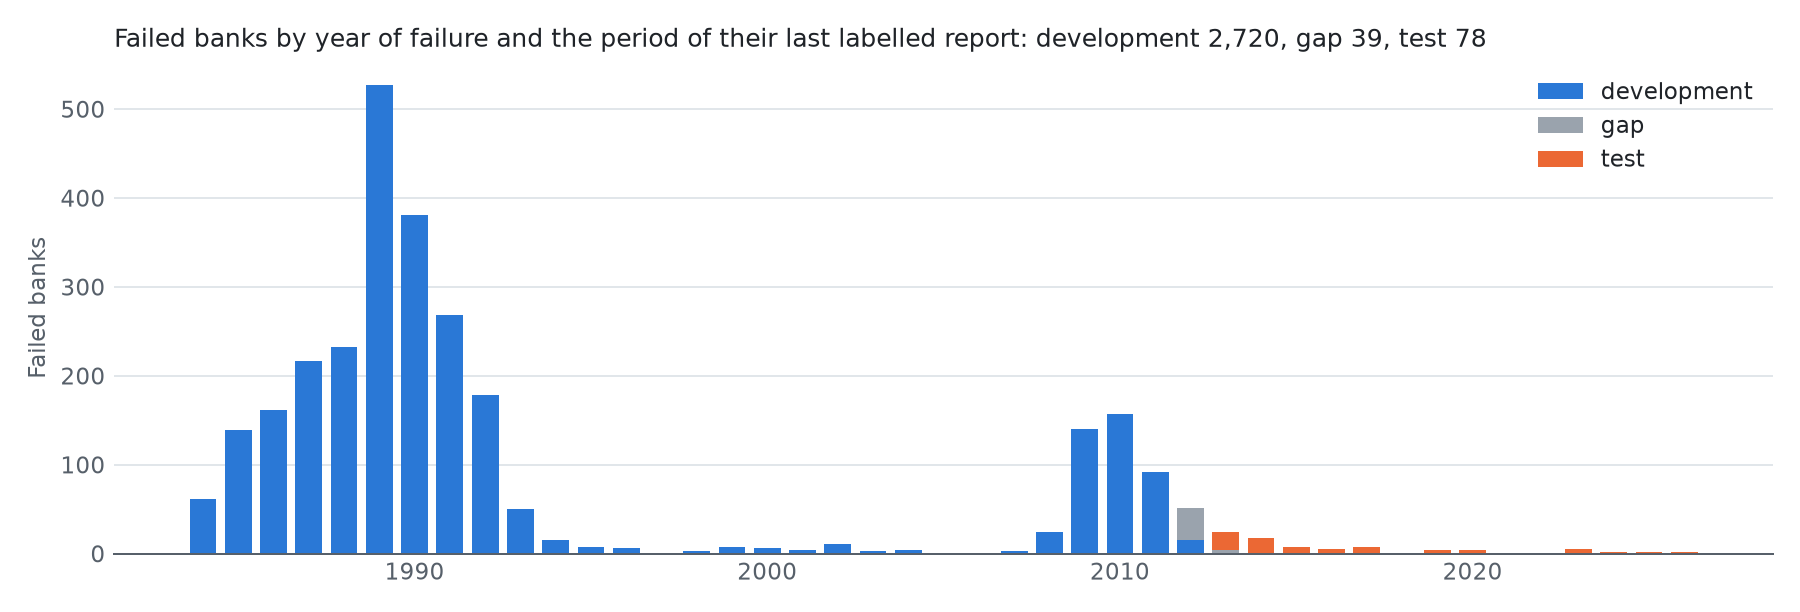

In [4]:
fig('fig_p4_split.png')

### Feature dictionary and screening on the training window only

In [5]:
csv('p4_feature_dictionary.csv')

,feature,pillar,kind,expected_sign,formula
0,eq_ta,C capital,num,-1,EQ / ASSET
1,tier1_lev,C capital,num,-1,"RBC1AAJ / 100, reported tier 1 leverage"
2,eq_ta_d4,C capital,num,-1,eq_ta minus eq_ta 4 quarters earlier
3,eq_ta_pct,C capital,num,-1,"rank of eq_ta among banks in the quarter, 0-1"
4,eq_st_gap,C capital,num,-1,eq_ta minus state median in the quarter
5,f_neg_equity,C capital,flag,1,EQ <= 0
6,npl,A assets,num,1,"NCLNLS / LNLSGR, noncurrent loans"
7,npa_ta,A assets,num,1,(NCLNLS + ORE) / ASSET
8,texas,A assets,num,1,"NPA / (NPA + max(EQ + LNATRES, 0)), bounded Texas ratio"
9,res_cov,A assets,num,-1,"LNATRES / (LNATRES + NCLNLS), bounded reserve coverage"


In [6]:
print(json.dumps(json.loads((R / 'p4_selected_features.json').read_text()), indent=1))

{
 "numeric": [
  "eq_ta",
  "eq_ta_d4",
  "npl",
  "texas",
  "res_cov",
  "res_ln",
  "nco_4q",
  "prov_4q",
  "npl_d4",
  "npl_st_gap",
  "con_ln",
  "ln_ta",
  "ln_g4",
  "roa_4q",
  "roa_q_d4",
  "cost_inc",
  "roa_std8",
  "loss_q4",
  "liq_ta",
  "bro_dep",
  "asset_g4",
  "st_npl_med",
  "st_loss_share",
  "st_fail_4q"
 ],
 "flags": [
  "f_neg_equity"
 ],
 "missing_indicators": [],
 "label": "y",
 "keys": [
  "CERT",
  "REPDTE"
 ],
 "split_column": "_split",
 "failed_banks_per_era": {
  "1986-89": 1473,
  "1990-94": 769,
  "1995-2006": 55
 },
 "screened_on": [
  "1986-03-31",
  "2006-12-31"
 ]
}


In [7]:
csv('p4_feature_screen.csv', 15)

,feature,pillar,kind,expected_sign,auc_pooled,auc_within_era,auc_1986-89,auc_1990-94,auc_1995-2006,null_max_era_pct,null_1986-89,null_1990-94,null_1995-2006,null_auc_pooled,null_auc_within_era,sign_stable,s1_complete,s2_signal,s3_stable,decision
0,roa_4q,E earnings,num,-1,0.0469,0.0911,0.0591,0.0574,0.1567,2.1596,2.1596,1.2583,1.5741,0.4940,0.4927,True,True,True,True,kept
1,tier1_lev,C capital,num,-1,0.0388,0.0935,0.0526,0.0355,0.1926,17.8697,17.8697,0.0173,0.0006,0.6201,0.5437,True,True,True,True,out: S4 duplicates eq_ta
2,roa_pct,E earnings,num,-1,0.0673,0.0965,0.0568,0.0706,0.1621,2.1596,2.1596,1.2583,1.5741,0.4940,0.4927,True,True,True,True,out: S4 duplicates roa_4q
3,eq_ta,C capital,num,-1,0.0394,0.1003,0.0624,0.0396,0.1990,0.0000,0.0000,0.0000,0.0000,NaN,NaN,True,True,True,True,kept
4,eq_ta_pct,C capital,num,-1,0.0650,0.1036,0.0622,0.0499,0.1986,0.0000,0.0000,0.0000,0.0000,NaN,NaN,True,True,True,True,out: S4 duplicates eq_ta
5,eq_st_gap,C capital,num,-1,0.0590,0.1082,0.0697,0.0512,0.2037,0.0000,0.0000,0.0000,0.0000,NaN,NaN,True,True,True,True,out: S4 duplicates eq_ta
6,eq_ta_d4,C capital,num,-1,0.1345,0.1762,0.1221,0.1558,0.2507,2.2980,2.2980,1.3175,1.6679,0.4935,0.4922,True,True,True,True,kept
7,asset_g4,S size,num,0,0.1922,0.2353,0.2370,0.1211,0.3476,2.2980,2.2980,1.3175,1.6679,0.4935,0.4922,True,True,True,True,kept
8,ln_g4,M loan mix,num,0,0.1949,0.2407,0.2391,0.1630,0.3200,2.5873,2.5873,1.6354,2.3188,0.4917,0.4907,True,True,True,True,kept
9,res_cov,A assets,num,-1,0.1821,0.2458,0.3121,0.2076,0.2176,0.9907,0.9514,0.6630,0.9907,0.4969,0.4967,True,True,True,True,kept


### Leakage tests, with deliberate controls (live, about 1 min)

In [8]:
run('src/p4_checks.py')

[PASS] truncated at 1990-12-31: 42 features unchanged  479,162 rows 
[PASS] truncated at 2008-12-31: 42 features unchanged  1,253,067 rows 
[PASS] truncated at 2019-12-31: 42 features unchanged  1,545,003 rows 
[PASS] control: all four leaky features are caught by truncation  {'leak_lead': 28469, 'leak_centred': 56802, 'leak_all_time': 3277232, 'leak_bank_max': 1570325}
[PASS] gap: 4 unused quarters between development and test  4 quarters
[PASS] the last development label ends before the first test quarter  
[PASS] test contains at least 50 failures  {'dev': 2755, 'gap': 59, 'test': 78}
[PASS] no bank's failure is labelled in both development and test  2,755 and 78 banks
[PASS] each row has one split; unlabelled rows only after 2025Q2  
[PASS] Part 4 train and validation also have a 4-quarter gap  4 quarters
[PASS] screening reads nothing after its training window  
[PASS] load_xy refuses the test period by default  
[PASS] fitted parameters equal an independent computation on trainin

In [9]:
csv('p4_checks.csv')

,test,result,detail
0,"key (CERT, REPDTE) is unique",PASS,"1,666,719 rows"
1,"gold has exactly the silver rows, and the same y",PASS,"y=1 rows 10,860"
2,no forbidden field and no _ column among the features,PASS,"42 candidates, 25 selected"
3,selected features are all in the registry,PASS,NaN
4,selected features exclude Institutions-snapshot fields,PASS,NaN
5,features are identical when every label-side column is removed first,PASS,"1,666,719 rows, 42 columns"
6,rebuild from bronze gives the stored feature table,PASS,NaN
7,truncated at 1990-12-31: 42 features unchanged,PASS,"479,162 rows"
8,truncated at 2008-12-31: 42 features unchanged,PASS,"1,253,067 rows"
9,truncated at 2019-12-31: 42 features unchanged,PASS,"1,545,003 rows"


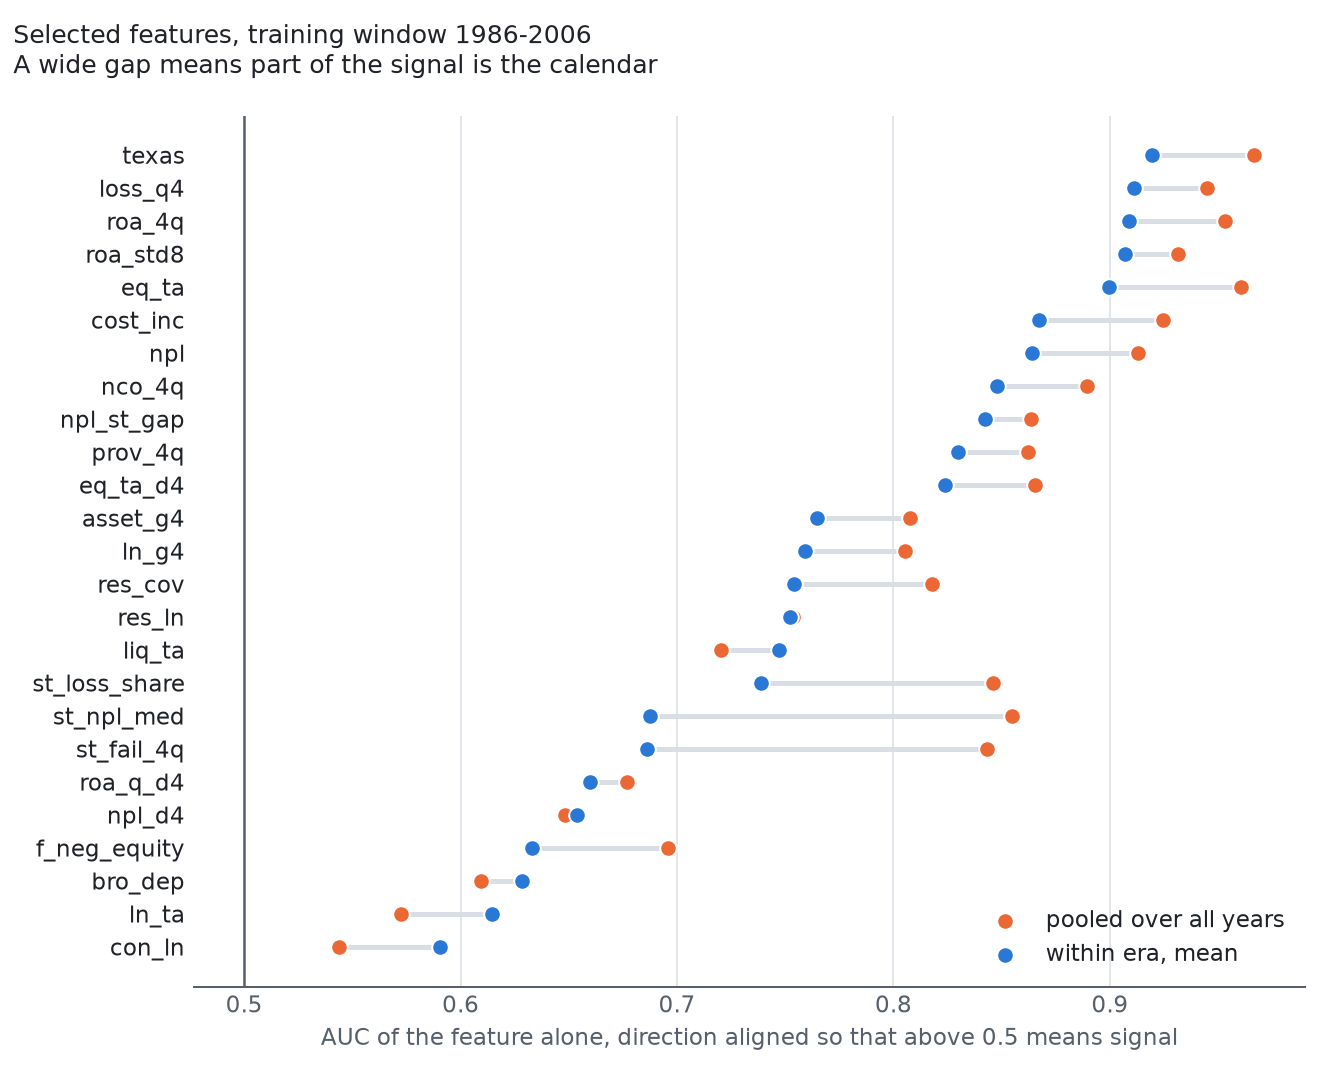

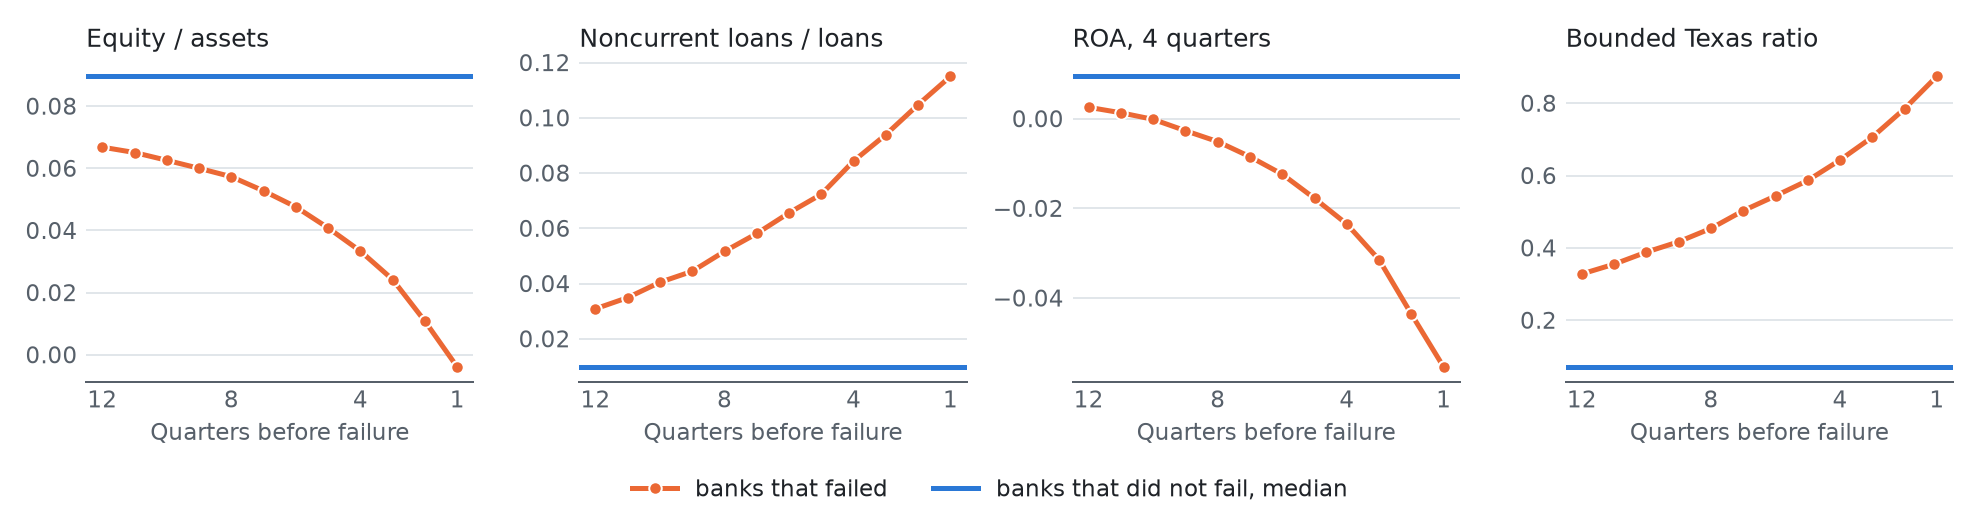

In [10]:
fig('fig_p4_signal.png'); fig('fig_p4_event_study.png')